In [3]:
'hello'

'hello'

In [5]:

import json
import random
import heapq

from pathlib import Path
from collections import Counter
from array import array

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ============================================================
# CONFIGURATION
# ============================================================

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/slm_data")

VOCAB_SIZE = 1000

# Maximum characters used to learn BPE merges.
# The complete training dataset will still be encoded later.
MAX_BPE_TRAIN_CHARS = 100_000

CSV_CHUNK_SIZE = 10_000

TEXT_COLUMN_OVERRIDE = None

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# FIND KAGGLE DATASET
# ============================================================

def find_dataset_files():

    candidates = []

    for train_file in INPUT_ROOT.rglob("train.csv"):

        validation_file = train_file.parent / "validation.csv"

        if validation_file.exists():

            candidates.append(
                (train_file, validation_file)
            )

    if not candidates:

        raise FileNotFoundError(
            "Could not find train.csv and validation.csv "
            "inside /kaggle/input."
        )

    # Prefer a folder with TinyStories in its path.
    candidates.sort(
        key=lambda pair: (
            "tinystories" not in str(pair[0]).lower(),
            len(str(pair[0]))
        )
    )

    if len(candidates) > 1:

        print("Multiple dataset pairs found:")

        for train_file, val_file in candidates:
            print(train_file, val_file)

        print("\nUsing the first matching pair.")

    return candidates[0]


TRAIN_CSV, VALIDATION_CSV = find_dataset_files()

print("Training file:", TRAIN_CSV)
print("Validation file:", VALIDATION_CSV)


# ============================================================
# DETECT STORY COLUMN
# ============================================================

def detect_text_column(csv_path):

    columns = pd.read_csv(
        csv_path,
        nrows=0
    ).columns.tolist()

    if TEXT_COLUMN_OVERRIDE is not None:

        if TEXT_COLUMN_OVERRIDE not in columns:

            raise ValueError(
                f"{TEXT_COLUMN_OVERRIDE} not found. "
                f"Available columns: {columns}"
            )

        return TEXT_COLUMN_OVERRIDE

    # Prefer exact matches.
    preferred = [
        "text",
        "story",
        "content",
        "document",
        "stories"
    ]

    column_lookup = {
        column.lower().strip(): column
        for column in columns
    }

    for name in preferred:

        if name in column_lookup:

            return column_lookup[name]

    # Look for a likely text column.
    for column in columns:

        name = column.lower()

        if any(
            word in name
            for word in ["text", "story", "content", "document"]
        ):

            return column

    # Use the only available column if there is just one.
    if len(columns) == 1:
        return columns[0]

    raise ValueError(
        f"Could not automatically identify the story column.\n"
        f"Available columns: {columns}\n"
        f"Set TEXT_COLUMN_OVERRIDE manually."
    )


TRAIN_COLUMN = detect_text_column(TRAIN_CSV)

VALIDATION_COLUMN = detect_text_column(VALIDATION_CSV)

print("\nTraining text column:", TRAIN_COLUMN)
print("Validation text column:", VALIDATION_COLUMN)


# ============================================================
# READ STORIES IN CHUNKS
# ============================================================

def iter_documents(csv_path, text_column):

    """
    Read stories in chunks instead of loading the
    complete CSV into RAM.
    """

    reader = pd.read_csv(
        csv_path,
        usecols=[text_column],
        chunksize=CSV_CHUNK_SIZE,
        dtype=str,
        keep_default_na=False
    )

    for chunk in reader:

        for value in chunk[text_column]:

            document = str(value).strip()

            if document:
                yield document


# ============================================================
# COLLECT BPE TRAINING SAMPLE
# ============================================================

def collect_bpe_sample():

    """
    Learn tokenizer merges from a limited sample of
    the training split only.

    This sample is NOT the final model training dataset.
    """

    sample = []
    total_characters = 0

    for document in iter_documents(
        TRAIN_CSV,
        TRAIN_COLUMN
    ):

        if len(document) > MAX_BPE_TRAIN_CHARS:
            continue

        if (
            total_characters + len(document)
            > MAX_BPE_TRAIN_CHARS
        ):
            break

        sample.append(document)
        total_characters += len(document)

        if total_characters >= MAX_BPE_TRAIN_CHARS:
            break

    if not sample:

        raise ValueError(
            "No documents collected for BPE training."
        )

    print("\nBPE training sample:")
    print("Documents:", len(sample))
    print("Characters:", total_characters)

    return sample


bpe_training_sample = collect_bpe_sample()


Training file: /kaggle/input/datasets/thedevastator/tinystories-narrative-classification/train.csv
Validation file: /kaggle/input/datasets/thedevastator/tinystories-narrative-classification/validation.csv

Training text column: text
Validation text column: text

BPE training sample:
Documents: 127
Characters: 99313


In [6]:

class BPETokenizer:

    def __init__(self, vocab_size=1000):

        if vocab_size < 259:
            raise ValueError(
                "Vocabulary size must be at least 259."
            )

        self.target_vocab_size = vocab_size

        self.merges = []
        self.merge_ranks = {}

        self.vocab = {}
        self.id_to_token = {}

        self._reset_vocab()

    # ========================================================
    # INITIAL VOCABULARY
    # ========================================================

    def _reset_vocab(self):

        self.vocab = {
            "<PAD>": 0,
            "<UNK>": 1,
            "<EOS>": 2
        }

        # Add all 256 possible byte values.
        for i in range(256):

            token = bytes([i])

            self.vocab[token] = len(self.vocab)

        self._update_vocab()

    def _update_vocab(self):

        self.id_to_token = {
            token_id: token
            for token, token_id in self.vocab.items()
        }

        self.vocab_size = len(self.vocab)

    # ========================================================
    # PAIR COUNTING
    # ========================================================

    @staticmethod
    def get_pairs(tokens):

        return Counter(
            zip(tokens, tokens[1:])
        )

    # ========================================================
    # MERGE A SELECTED PAIR
    # ========================================================

    @staticmethod
    def merge_pair(tokens, pair):

        merged = []
        i = 0

        while i < len(tokens):

            if (
                i + 1 < len(tokens)
                and (tokens[i], tokens[i + 1]) == pair
            ):

                merged.append(
                    tokens[i] + tokens[i + 1]
                )

                i += 2

            else:

                merged.append(tokens[i])
                i += 1

        return merged

    # ========================================================
    # TRAIN BPE
    # ========================================================

    def fit(self, documents):

        print("=" * 50)
        print("STARTING BPE TRAINING")
        print("=" * 50)

        self._reset_vocab()

        self.merges = []

        # Convert each document into UTF-8 bytes.
        corpus = [

            [
                bytes([b])
                for b in document.encode("utf-8")
            ]

            for document in documents

            if document
        ]

        if not corpus:

            raise ValueError(
                "Cannot train tokenizer on empty corpus."
            )

        # Continue until target vocabulary is reached.
        while len(self.vocab) < self.target_vocab_size:

            pair_counts = Counter()

            # Count pairs independently in every document.
            for tokens in corpus:

                pair_counts.update(
                    self.get_pairs(tokens)
                )

            if not pair_counts:
                break

            best_pair = None

            # Select the most frequent pair that creates
            # a genuinely new vocabulary token.
            for pair, frequency in pair_counts.most_common():

                if frequency < 2:
                    break

                new_token = pair[0] + pair[1]

                if new_token not in self.vocab:

                    best_pair = pair
                    break

            if best_pair is None:
                break

            # Apply the merge throughout the corpus.
            corpus = [

                self.merge_pair(tokens, best_pair)

                for tokens in corpus
            ]

            # Save the merge rule.
            self.merges.append(best_pair)

            new_token = best_pair[0] + best_pair[1]

            self.vocab[new_token] = len(self.vocab)

            merge_number = len(self.merges)

            if merge_number % 100 == 0:

                print(
                    f"Merges: {merge_number} | "
                    f"Vocabulary: {len(self.vocab)}"
                )

        self._update_vocab()

        self._build_merge_ranks()

        print("\nBPE training completed.")
        print("Target vocabulary:", self.target_vocab_size)
        print("Actual vocabulary:", self.vocab_size)
        print("Total merges:", len(self.merges))

    # ========================================================
    # BUILD MERGE RANKS
    # ========================================================

    def _build_merge_ranks(self):

        self.merge_ranks = {

            pair: rank

            for rank, pair in enumerate(self.merges)
        }

    # ========================================================
    # EFFICIENT BPE TOKENIZATION
    # ========================================================

    def tokenize(self, text):

        """
        Apply merges in learned priority order.

        A priority queue updates only neighboring pairs
        after a merge, rather than rescanning the complete
        document for every merge rule.
        """

        tokens = [
            bytes([b])
            for b in text.encode("utf-8")
        ]

        n = len(tokens)

        if n <= 1:
            return tokens

        # Doubly linked list represented using arrays.
        previous = [
            i - 1 for i in range(n)
        ]

        next_token = [
            i + 1 for i in range(n)
        ]

        next_token[-1] = -1

        active = [True] * n

        heap = []

        # Add a pair to the priority queue if it has
        # a learned merge rule.
        def add_pair(i, j):

            if i == -1 or j == -1:
                return

            rank = self.merge_ranks.get(
                (tokens[i], tokens[j])
            )

            if rank is not None:

                heapq.heappush(
                    heap,
                    (rank, i, j)
                )

        # Initialize all adjacent pairs.
        for i in range(n - 1):

            add_pair(i, i + 1)

        # Repeatedly apply the highest-priority merge.
        while heap:

            rank, i, j = heapq.heappop(heap)

            # Ignore outdated queue entries.
            if not active[i] or not active[j]:
                continue

            if next_token[i] != j:
                continue

            current_rank = self.merge_ranks.get(
                (tokens[i], tokens[j])
            )

            if current_rank != rank:
                continue

            # Merge the two tokens.
            tokens[i] = tokens[i] + tokens[j]

            # Remove the second token.
            active[j] = False

            right = next_token[j]

            next_token[i] = right

            if right != -1:

                previous[right] = i

            # Only neighboring pairs can have changed.
            left = previous[i]

            add_pair(left, i)
            add_pair(i, right)

        # Reconstruct final token sequence.
        result = []

        i = 0

        while i != -1:

            if active[i]:
                result.append(tokens[i])

            i = next_token[i]

        return result

    # ========================================================
    # ENCODE TEXT INTO TOKEN IDS
    # ========================================================

    def encode(self, text):

        tokens = self.tokenize(text)

        return [
            self.vocab[token]
            for token in tokens
        ]

    # ========================================================
    # ENCODE ONE DOCUMENT + EOS
    # ========================================================

    def encode_document(self, text):

        return (
            self.encode(text)
            + [self.vocab["<EOS>"]]
        )

    # ========================================================
    # DECODE TOKEN IDS INTO TEXT
    # ========================================================

    def decode(self, ids):

        byte_tokens = []

        for token_id in ids:

            token_id = int(token_id)

            if token_id not in self.id_to_token:

                raise ValueError(
                    f"Unknown token ID: {token_id}"
                )

            token = self.id_to_token[token_id]

            if token_id == self.vocab["<PAD>"]:

                continue

            elif token_id == self.vocab["<EOS>"]:

                byte_tokens.append(b"\n\n")

            elif token_id == self.vocab["<UNK>"]:

                byte_tokens.append(
                    "\uFFFD".encode("utf-8")
                )

            elif isinstance(token, bytes):

                byte_tokens.append(token)

        return b"".join(byte_tokens).decode(
            "utf-8",
            errors="replace"
        )

    # ========================================================
    # SAVE TOKENIZER
    # ========================================================

    def save(self, path):

        path = Path(path)

        path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        data = {

            "version": 1,

            "target_vocab_size": self.target_vocab_size,

            "vocab_size": self.vocab_size,

            "special_tokens": {
                "<PAD>": 0,
                "<UNK>": 1,
                "<EOS>": 2
            },

            "merges": [

                [a.hex(), b.hex()]

                for a, b in self.merges
            ]
        }

        with path.open("w", encoding="utf-8") as file:

            json.dump(
                data,
                file,
                indent=2
            )

        print("Tokenizer saved:", path)

    # ========================================================
    # LOAD TOKENIZER
    # ========================================================

    def load(self, path):

        with Path(path).open(
            "r",
            encoding="utf-8"
        ) as file:

            data = json.load(file)

        self.target_vocab_size = data[
            "target_vocab_size"
        ]

        self._reset_vocab()

        self.merges = [

            (
                bytes.fromhex(a),
                bytes.fromhex(b)
            )

            for a, b in data["merges"]
        ]

        for a, b in self.merges:

            new_token = a + b

            if new_token not in self.vocab:

                self.vocab[new_token] = len(self.vocab)

        self._update_vocab()

        if self.vocab_size != data["vocab_size"]:

            raise ValueError(
                "Vocabulary size mismatch while loading tokenizer."
            )

        self._build_merge_ranks()

        print("Tokenizer loaded.")
        print("Vocabulary size:", self.vocab_size)


In [7]:

# ============================================================
# 1. INITIALIZE AND TRAIN TOKENIZER
# ============================================================

tokenizer = BPETokenizer(
    vocab_size=VOCAB_SIZE
)

tokenizer.fit(bpe_training_sample)


# ============================================================
# 2. SAVE TOKENIZER
# ============================================================

tokenizer_path = OUTPUT_DIR / "tokenizer.json"

tokenizer.save(tokenizer_path)


# ============================================================
# 3. ENCODE COMPLETE CSV DATASET
# ============================================================

def encode_csv(csv_path, text_column, output_name):

    """
    Encode every story in a CSV file.

    Stories are processed in chunks to avoid loading
    the complete dataset into memory.

    EOS is appended after every story.
    """

    token_buffer = array("i")

    document_count = 0

    print(f"\nEncoding: {output_name}")

    for document in tqdm(
        iter_documents(csv_path, text_column),
        desc=output_name
    ):

        document_tokens = tokenizer.encode_document(
            document
        )

        token_buffer.extend(document_tokens)

        document_count += 1

    # Kaggle uses a platform where array('i') is 32-bit.
    if token_buffer.itemsize != 4:

        raise RuntimeError(
            "Expected 32-bit integers for token storage."
        )

    token_array = np.frombuffer(
        token_buffer,
        dtype=np.int32
    )

    output_path = OUTPUT_DIR / output_name

    np.save(
        output_path,
        token_array
    )

    print("\nEncoding completed.")
    print("Documents:", document_count)
    print("Total tokens:", len(token_array))
    print("Output:", output_path)

    return {
        "documents": document_count,
        "tokens": len(token_array),
        "file": output_name
    }


# ============================================================
# 4. ENCODE TRAINING DATA
# ============================================================

train_stats = encode_csv(
    csv_path=TRAIN_CSV,
    text_column=TRAIN_COLUMN,
    output_name="train_tokens.npy"
)


# ============================================================
# 5. ENCODE VALIDATION DATA
# ============================================================

validation_stats = encode_csv(
    csv_path=VALIDATION_CSV,
    text_column=VALIDATION_COLUMN,
    output_name="validation_tokens.npy"
)


# ============================================================
# 6. SAVE TOKENIZER CONFIGURATION
# ============================================================

tokenizer_config = {

    "vocab_size": tokenizer.vocab_size,

    "pad_token_id": tokenizer.vocab["<PAD>"],

    "unk_token_id": tokenizer.vocab["<UNK>"],

    "eos_token_id": tokenizer.vocab["<EOS>"],

    "target_vocab_size": VOCAB_SIZE
}

with (
    OUTPUT_DIR / "tokenizer_config.json"
).open("w", encoding="utf-8") as file:

    json.dump(
        tokenizer_config,
        file,
        indent=2
    )


# ============================================================
# 7. SAVE DATASET METADATA
# ============================================================

metadata = {

    "dataset": "TinyStories",

    "training_file": str(TRAIN_CSV),

    "validation_file": str(VALIDATION_CSV),

    "training_text_column": TRAIN_COLUMN,

    "validation_text_column": VALIDATION_COLUMN,

    "tokenizer_vocab_size": tokenizer.vocab_size,

    "number_of_merges": len(tokenizer.merges),

    "bpe_training_char_limit": MAX_BPE_TRAIN_CHARS,

    "special_tokens": tokenizer_config,

    "training": train_stats,

    "validation": validation_stats
}

with (
    OUTPUT_DIR / "dataset_metadata.json"
).open("w", encoding="utf-8") as file:

    json.dump(
        metadata,
        file,
        indent=2
    )


# ============================================================
# 8. VERIFY TOKENIZER
# ============================================================

print("\nTOKENIZER VERIFICATION")

sample_text = bpe_training_sample[0]

encoded = tokenizer.encode(sample_text)

decoded = tokenizer.decode(encoded)

assert decoded == sample_text, (
    "Encoding and decoding verification failed!"
)

# Verify that saved tokenizer can be loaded.
loaded_tokenizer = BPETokenizer()

loaded_tokenizer.load(tokenizer_path)

loaded_encoded = loaded_tokenizer.encode(sample_text)

assert encoded == loaded_encoded, (
    "Tokenizer save/load verification failed!"
)

print("Encoding: PASSED")
print("Decoding: PASSED")
print("Save/load: PASSED")


# ============================================================
# 9. FINAL REPORT
# ============================================================

print("\n" + "=" * 55)
print("PREPROCESSING COMPLETED")
print("=" * 55)

print("Vocabulary size:", tokenizer.vocab_size)

print("BPE merges:", len(tokenizer.merges))

print("Training tokens:", train_stats["tokens"])

print("Validation tokens:", validation_stats["tokens"])

print("\nGenerated files:")

for file in sorted(OUTPUT_DIR.iterdir()):

    if file.is_file():

        size_mb = file.stat().st_size / (1024 * 1024)

        print(f"{file.name:<30} {size_mb:.2f} MB")


STARTING BPE TRAINING
Merges: 100 | Vocabulary: 359
Merges: 200 | Vocabulary: 459
Merges: 300 | Vocabulary: 559
Merges: 400 | Vocabulary: 659
Merges: 500 | Vocabulary: 759
Merges: 600 | Vocabulary: 859
Merges: 700 | Vocabulary: 959

BPE training completed.
Target vocabulary: 1000
Actual vocabulary: 1000
Total merges: 741
Tokenizer saved: /kaggle/working/slm_data/tokenizer.json

Encoding: train_tokens.npy


train_tokens.npy: 0it [00:00, ?it/s]


Encoding completed.
Documents: 2119489
Total tokens: 606047153
Output: /kaggle/working/slm_data/train_tokens.npy

Encoding: validation_tokens.npy


validation_tokens.npy: 0it [00:00, ?it/s]


Encoding completed.
Documents: 21990
Total tokens: 6089728
Output: /kaggle/working/slm_data/validation_tokens.npy

TOKENIZER VERIFICATION
Tokenizer loaded.
Vocabulary size: 1000
Encoding: PASSED
Decoding: PASSED
Save/load: PASSED

PREPROCESSING COMPLETED
Vocabulary size: 1000
BPE merges: 741
Training tokens: 606047153
Validation tokens: 6089728

Generated files:
dataset_metadata.json          0.00 MB
tokenizer.json                 0.03 MB
tokenizer_config.json          0.00 MB
train_tokens.npy               2311.89 MB
validation_tokens.npy          23.23 MB


In [8]:
vocab_size = tokenizer_config["vocab_size"]

In [9]:

import os
import json
import math
import random
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from tqdm.auto import tqdm


# ==========================================
# RANDOM SEED
# ==========================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ==========================================
# DEVICE
# ==========================================

if torch.cuda.is_available():

    device = torch.device("cuda")

elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():

    device = torch.device("mps")

else:

    device = torch.device("cpu")


print("PyTorch version:", torch.__version__)
print("Device:", device)

if device.type == "cuda":

    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


In [10]:

# ==========================================
# PATHS
# ==========================================

DATA_DIR = Path("/kaggle/working/slm_data")

TRAIN_PATH = DATA_DIR / "train_tokens.npy"

VALIDATION_PATH = DATA_DIR / "validation_tokens.npy"

TOKENIZER_CONFIG_PATH = DATA_DIR / "tokenizer_config.json"


# ==========================================
# LOAD TOKENIZER CONFIGURATION
# ==========================================

with open(
    TOKENIZER_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:

    tokenizer_config = json.load(file)


VOCAB_SIZE = tokenizer_config["vocab_size"]

PAD_TOKEN_ID = tokenizer_config["pad_token_id"]

UNK_TOKEN_ID = tokenizer_config["unk_token_id"]

EOS_TOKEN_ID = tokenizer_config["eos_token_id"]


# ==========================================
# LOAD TOKEN ARRAYS
# ==========================================

train_tokens = np.load(
    TRAIN_PATH,
    mmap_mode="r"
)

validation_tokens = np.load(
    VALIDATION_PATH,
    mmap_mode="r"
)


# ==========================================
# VALIDATE DATASETS
# ==========================================

assert train_tokens.ndim == 1

assert validation_tokens.ndim == 1

assert len(train_tokens) > 1

assert len(validation_tokens) > 1

assert train_tokens.dtype == np.int32

assert validation_tokens.dtype == np.int32


def validate_token_ids(data, name, vocab_size):

    minimum = int(data.min())
    maximum = int(data.max())

    if minimum < 0 or maximum >= vocab_size:

        raise ValueError(
            f"{name} contains invalid token IDs. "
            f"Range: {minimum} to {maximum}, "
            f"vocabulary size: {vocab_size}"
        )

    print(
        f"{name}: {len(data):,} tokens | "
        f"ID range: {minimum} to {maximum}"
    )


validate_token_ids(
    train_tokens,
    "Training",
    VOCAB_SIZE
)

validate_token_ids(
    validation_tokens,
    "Validation",
    VOCAB_SIZE
)


print("\nTokenizer configuration:")
print("Vocabulary size:", VOCAB_SIZE)
print("PAD:", PAD_TOKEN_ID)
print("UNK:", UNK_TOKEN_ID)
print("EOS:", EOS_TOKEN_ID)


Training: 606,047,153 tokens | ID range: 2 to 999
Validation: 6,089,728 tokens | ID range: 2 to 999

Tokenizer configuration:
Vocabulary size: 1000
PAD: 0
UNK: 1
EOS: 2


In [12]:

import math
import torch
import torch.nn as nn


class WordEmbedding(nn.Module):

    def __init__(self, vocab_size, embedding_dim=128, padding_idx=0):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )

    def forward(self, token_ids):
        return self.embedding(token_ids)


class PositionalEncoding(nn.Module):

    def __init__(self, embedding_dim=128, max_seq_len=128):
        super().__init__()

        pe = torch.zeros(max_seq_len, embedding_dim)

        position = torch.arange(
            max_seq_len,
            dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, embedding_dim, 2).float()
            * (-math.log(10000.0) / embedding_dim)
        )

        pe[:, 0::2] = torch.sin(position * div_term)

        pe[:, 1::2] = torch.cos(
            position * div_term[:pe[:, 1::2].shape[1]]
        )

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, token_ids):

        seq_len = token_ids.shape[-1]

        if seq_len > self.pe.shape[1]:
            raise ValueError("Sequence exceeds maximum context length.")

        return self.pe[0, :seq_len, :]


class MaskedMultiHeadAttention(nn.Module):

    def __init__(self, embedding_dim=128, num_heads=4):
        super().__init__()

        if embedding_dim % num_heads != 0:
            raise ValueError("Embedding dimension must be divisible by heads.")

        self.embedding_dim = embedding_dim
        self.num_heads = num_heads
        self.head_dim = embedding_dim // num_heads

        self.W_Q = nn.Linear(embedding_dim, embedding_dim)
        self.W_K = nn.Linear(embedding_dim, embedding_dim)
        self.W_V = nn.Linear(embedding_dim, embedding_dim)
        self.W_O = nn.Linear(embedding_dim, embedding_dim)

    def forward(self, input_features, padding_mask=None):

        if input_features.ndim != 3:
            raise ValueError("Expected input shape (batch, seq_len, embedding_dim).")

        batch_size, seq_len, _ = input_features.shape

        Q = self.W_Q(input_features)
        K = self.W_K(input_features)
        V = self.W_V(input_features)

        Q = Q.view(
            batch_size, seq_len,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        K = K.view(
            batch_size, seq_len,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        V = V.view(
            batch_size, seq_len,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        scores = (
            Q @ K.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        # Causal mask: prevent access to future tokens.
        causal_mask = torch.triu(
            torch.ones(
                seq_len, seq_len,
                dtype=torch.bool,
                device=input_features.device
            ),
            diagonal=1
        )

        scores = scores.masked_fill(
            causal_mask[None, None, :, :],
            float("-inf")
        )

        # Padding mask: prevent attention to padding keys.
        if padding_mask is not None:

            scores = scores.masked_fill(
                padding_mask[:, None, None, :],
                float("-inf")
            )

        attention_weights = torch.softmax(scores, dim=-1)

        attention_weights = torch.nan_to_num(
            attention_weights,
            nan=0.0
        )

        output = attention_weights @ V

        output = output.transpose(1, 2).contiguous().view(
            batch_size,
            seq_len,
            self.embedding_dim
        )

        return self.W_O(output)


class AddAndNormalize(nn.Module):

    def __init__(self, embedding_dim=128):
        super().__init__()

        self.layer_norm = nn.LayerNorm(embedding_dim)

    def forward(self, x, sublayer_output):

        return self.layer_norm(x + sublayer_output)


class FeedForward(nn.Module):

    def __init__(self, embedding_dim=128, ff_dim=512):
        super().__init__()

        self.linear1 = nn.Linear(embedding_dim, ff_dim)
        self.activation = nn.ReLU()
        self.linear2 = nn.Linear(ff_dim, embedding_dim)

    def forward(self, x):

        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)

        return x


class TransformerDecoderBlock(nn.Module):

    def __init__(
        self,
        embedding_dim=128,
        num_heads=4,
        ff_dim=512
    ):
        super().__init__()

        self.masked_attention = MaskedMultiHeadAttention(
            embedding_dim,
            num_heads
        )

        self.add_norm1 = AddAndNormalize(embedding_dim)

        self.feed_forward = FeedForward(
            embedding_dim,
            ff_dim
        )

        self.add_norm2 = AddAndNormalize(embedding_dim)

    def forward(self, x, padding_mask=None):

        attention_output = self.masked_attention(
            x,
            padding_mask
        )

        x = self.add_norm1(x, attention_output)

        ff_output = self.feed_forward(x)

        x = self.add_norm2(x, ff_output)

        return x


class NextWordPredictor(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_heads=4,
        ff_dim=512,
        num_layers=2,
        max_seq_len=128,
        pad_token_id=0
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.max_seq_len = max_seq_len
        self.pad_token_id = pad_token_id

        self.embedding = WordEmbedding(
            vocab_size,
            embedding_dim,
            pad_token_id
        )

        self.positional_encoding = PositionalEncoding(
            embedding_dim,
            max_seq_len
        )

        self.decoder_blocks = nn.ModuleList([

            TransformerDecoderBlock(
                embedding_dim,
                num_heads,
                ff_dim
            )

            for _ in range(num_layers)
        ])

        self.final_norm = nn.LayerNorm(embedding_dim)

        self.output_layer = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, token_ids):

        if token_ids.ndim == 1:
            token_ids = token_ids.unsqueeze(0)

        if token_ids.ndim != 2:
            raise ValueError("Expected 1D or 2D token IDs.")

        token_ids = token_ids.long()

        if token_ids.shape[1] == 0:
            raise ValueError("Input cannot be empty.")

        if token_ids.shape[1] > self.max_seq_len:
            raise ValueError("Input exceeds maximum context length.")

        if torch.any(token_ids < 0) or torch.any(
            token_ids >= self.vocab_size
        ):
            raise ValueError("Invalid token ID.")

        padding_mask = token_ids.eq(self.pad_token_id)

        x = self.embedding(token_ids)

        positional = self.positional_encoding(token_ids)

        x = x + positional.unsqueeze(0)

        for block in self.decoder_blocks:

            x = block(
                x,
                padding_mask=padding_mask
            )

        x = self.final_norm(x)

        logits = self.output_layer(x)

        return logits


In [14]:

# ==========================================
# MODEL CONFIGURATION
# ==========================================

MODEL_CONFIG = {

    "vocab_size": VOCAB_SIZE,

    "embedding_dim": 128,

    "num_heads": 4,

    "ff_dim": 512,

    "num_layers": 2,

    "max_seq_len": 128,

    "pad_token_id": PAD_TOKEN_ID
}


# ==========================================
# INITIALIZE TRANSFORMER
# ==========================================

model = NextWordPredictor(
    vocab_size=MODEL_CONFIG["vocab_size"],
    embedding_dim=MODEL_CONFIG["embedding_dim"],
    num_heads=MODEL_CONFIG["num_heads"],
    ff_dim=MODEL_CONFIG["ff_dim"],
    num_layers=MODEL_CONFIG["num_layers"],
    max_seq_len=MODEL_CONFIG["max_seq_len"],
    pad_token_id=MODEL_CONFIG["pad_token_id"]
)


model = model.to(device)


print("Transformer initialized successfully.")
print("\nModel configuration:")

for key, value in MODEL_CONFIG.items():

    print(f"{key}: {value}")


Transformer initialized successfully.

Model configuration:
vocab_size: 1000
embedding_dim: 128
num_heads: 4
ff_dim: 512
num_layers: 2
max_seq_len: 128
pad_token_id: 0


In [15]:

# ==========================================
# PARAMETER COUNT
# ==========================================

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")


# ==========================================
# FORWARD PASS TEST
# ==========================================

dummy_input = torch.randint(
    3,
    VOCAB_SIZE,
    (2, MODEL_CONFIG["max_seq_len"]),
    dtype=torch.long,
    device=device
)

model.eval()

with torch.no_grad():
    output = model(dummy_input)


print("\nInput shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(output.shape))

expected_shape = (
    2,
    MODEL_CONFIG["max_seq_len"],
    VOCAB_SIZE
)

assert tuple(output.shape) == expected_shape
assert torch.isfinite(output).all()

if VOCAB_SIZE == 1000:
    assert trainable_parameters == 653800

print("\nArchitecture verification: PASSED")


Total parameters: 653,800
Trainable parameters: 653,800

Input shape: (2, 128)
Output shape: (2, 128, 1000)

Architecture verification: PASSED


In [16]:

# ==========================================
# TRAINING PARAMETERS
# ==========================================

BATCH_SIZE = 32
BLOCK_SIZE = MODEL_CONFIG["max_seq_len"]


# ==========================================
# BATCH GENERATOR
# ==========================================

def get_batch(data, batch_size, block_size):

    max_start = len(data) - block_size

    if max_start <= 0:
        raise ValueError("Dataset is smaller than the context window.")

    starts = np.random.randint(
        0,
        max_start,
        size=batch_size
    )

    x_batch = []
    y_batch = []

    for start in starts:

        sequence = np.asarray(
            data[start:start + block_size + 1],
            dtype=np.int64
        )

        x_batch.append(sequence[:-1])
        y_batch.append(sequence[1:])

    x_batch = np.stack(x_batch)
    y_batch = np.stack(y_batch)

    x = torch.from_numpy(x_batch).to(device)
    y = torch.from_numpy(y_batch).to(device)

    return x, y


# ==========================================
# VERIFY BATCHES
# ==========================================

x, y = get_batch(
    train_tokens,
    BATCH_SIZE,
    BLOCK_SIZE
)

print("Input shape:", x.shape)
print("Target shape:", y.shape)

print("\nInput:", x[0, :10].cpu().tolist())
print("Target:", y[0, :10].cpu().tolist())

assert x.shape == (BATCH_SIZE, BLOCK_SIZE)
assert y.shape == (BATCH_SIZE, BLOCK_SIZE)

assert torch.equal(x[:, 1:], y[:, :-1])

print("\nBatch generation: PASSED")


Input shape: torch.Size([32, 128])
Target shape: torch.Size([32, 128])

Input: [541, 359, 118, 347, 661, 124, 469, 299, 267, 669]
Target: [359, 118, 347, 661, 124, 469, 299, 267, 669, 508]

Batch generation: PASSED


In [17]:

@torch.inference_mode()
def evaluate_loss(model, data, block_size, batch_size=32):

    model.eval()

    total_loss = 0.0
    total_tokens = 0

    num_transitions = len(data) - 1

    starts = np.arange(
        0,
        num_transitions,
        block_size
    )

    for batch_start in range(0, len(starts), batch_size):

        batch_starts = starts[
            batch_start:batch_start + batch_size
        ]

        current_batch_size = len(batch_starts)

        x_np = np.full(
            (current_batch_size, block_size),
            PAD_TOKEN_ID,
            dtype=np.int64
        )

        y_np = np.full(
            (current_batch_size, block_size),
            -100,
            dtype=np.int64
        )

        for row, start in enumerate(batch_starts):

            length = min(
                block_size,
                num_transitions - start
            )

            x_np[row, :length] = np.asarray(
                data[start:start + length],
                dtype=np.int64
            )

            y_np[row, :length] = np.asarray(
                data[start + 1:start + length + 1],
                dtype=np.int64
            )

        x = torch.from_numpy(x_np).to(device)
        y = torch.from_numpy(y_np).to(device)

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, VOCAB_SIZE),
            y.reshape(-1),
            ignore_index=-100,
            reduction="sum"
        )

        valid_tokens = (y != -100).sum().item()

        total_loss += loss.item()
        total_tokens += valid_tokens

    if total_tokens == 0:
        raise ValueError("No validation targets were evaluated.")

    average_loss = total_loss / total_tokens

    perplexity = math.exp(average_loss)

    return {
        "loss": average_loss,
        "perplexity": perplexity,
        "evaluated_tokens": total_tokens
    }


# ==========================================
# INITIAL VALIDATION
# ==========================================

initial_validation = evaluate_loss(
    model,
    validation_tokens,
    BLOCK_SIZE,
    BATCH_SIZE
)

print("Initial validation loss:",
      round(initial_validation["loss"], 4))

print("Initial perplexity:",
      round(initial_validation["perplexity"], 4))

print("Evaluated tokens:",
      f'{initial_validation["evaluated_tokens"]:,}')

assert (
    initial_validation["evaluated_tokens"]
    == len(validation_tokens) - 1
)


Initial validation loss: 7.0991
Initial perplexity: 1210.9088
Evaluated tokens: 6,089,727


In [18]:

# ==========================================
# TRAINING CONFIGURATION
# ==========================================

TRAIN_CONFIG = {

    "epochs": 30,

    "batch_size": BATCH_SIZE,

    "block_size": BLOCK_SIZE,

    "learning_rate": 3e-4,

    "weight_decay": 0.01,

    "gradient_clip": 1.0,

    "early_stopping_patience": 5,

    "min_delta": 0.001,

    "max_steps_per_epoch": 500
}


# ==========================================
# OPTIMIZER
# ==========================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"]
)


# ==========================================
# SCHEDULER
# ==========================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)


# ==========================================
# LOSS
# ==========================================

criterion = nn.CrossEntropyLoss()


# ==========================================
# CHECKPOINT DIRECTORY
# ==========================================

CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_model.pth"


print("Optimizer:", type(optimizer).__name__)
print("Scheduler:", type(scheduler).__name__)
print("Learning rate:", TRAIN_CONFIG["learning_rate"])
print("Maximum epochs:", TRAIN_CONFIG["epochs"])


Optimizer: AdamW
Scheduler: ReduceLROnPlateau
Learning rate: 0.0003
Maximum epochs: 30


In [19]:

# ==========================================
# TRAIN ONE EPOCH
# ==========================================

def train_one_epoch(
    model,
    data,
    optimizer,
    batch_size,
    block_size
):

    model.train()

    total_loss = 0.0
    total_tokens = 0

    steps = max(
        1,
        len(data) // (batch_size * block_size)
    )

    steps = min(
        steps,
        TRAIN_CONFIG["max_steps_per_epoch"]
    )

    progress = tqdm(
        range(steps),
        desc="Training",
        leave=False
    )

    for step in progress:

        x, y = get_batch(
            data,
            batch_size,
            block_size
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(x)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            y.reshape(-1)
        )

        loss.backward()

        # Prevent excessively large gradients.
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            TRAIN_CONFIG["gradient_clip"]
        )

        optimizer.step()

        token_count = y.numel()

        total_loss += loss.item() * token_count
        total_tokens += token_count

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / total_tokens


# ==========================================
# FULL TRAINING LOOP
# ==========================================

history = []

best_val_loss = float("inf")
patience_counter = 0

training_start = time.time()


for epoch in range(TRAIN_CONFIG["epochs"]):

    epoch_start = time.time()

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch + 1}/{TRAIN_CONFIG['epochs']}")
    print("=" * 60)

    # TRAINING
    train_loss = train_one_epoch(
        model=model,
        data=train_tokens,
        optimizer=optimizer,
        batch_size=BATCH_SIZE,
        block_size=BLOCK_SIZE
    )

    # VALIDATION
    validation_results = evaluate_loss(
        model=model,
        data=validation_tokens,
        block_size=BLOCK_SIZE,
        batch_size=BATCH_SIZE
    )

    val_loss = validation_results["loss"]
    val_perplexity = validation_results["perplexity"]

    # LEARNING RATE UPDATE
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start

    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation perplexity: {val_perplexity:.4f}")
    print(f"Learning rate: {current_lr:.8f}")
    print(f"Epoch time: {epoch_time:.2f} seconds")

    # RECORD HISTORY
    history.append({

        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_perplexity": val_perplexity,
        "learning_rate": current_lr,
        "epoch_time": epoch_time
    })

    # SAVE BEST CHECKPOINT
    if val_loss < best_val_loss - TRAIN_CONFIG["min_delta"]:

        best_val_loss = val_loss
        patience_counter = 0

        checkpoint = {

            "epoch": epoch + 1,

            "model_state_dict": model.state_dict(),

            "optimizer_state_dict": optimizer.state_dict(),

            "best_val_loss": best_val_loss,

            "model_config": MODEL_CONFIG,

            "train_config": TRAIN_CONFIG,

            "tokenizer_config": tokenizer_config
        }

        torch.save(
            checkpoint,
            BEST_MODEL_PATH
        )

        print("Best checkpoint saved.")

    else:

        patience_counter += 1

        print(
            f"No sufficient improvement: "
            f"{patience_counter}/"
            f"{TRAIN_CONFIG['early_stopping_patience']}"
        )

    # EARLY STOPPING
    if patience_counter >= TRAIN_CONFIG["early_stopping_patience"]:

        print("\nEarly stopping triggered.")
        break


training_time = time.time() - training_start

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print("Best validation loss:", best_val_loss)
print("Training time:", round(training_time, 2), "seconds")
print("Checkpoint:", BEST_MODEL_PATH)



EPOCH 1/30


Training:   0%|          | 0/500 [00:00<?, ?it/s]

Training loss: 5.1503
Validation loss: 4.2492
Validation perplexity: 70.0494
Learning rate: 0.00030000
Epoch time: 12.21 seconds
Best checkpoint saved.

EPOCH 2/30


Training:   0%|          | 0/500 [00:00<?, ?it/s]

Training loss: 4.0023
Validation loss: 3.8335
Validation perplexity: 46.2261
Learning rate: 0.00030000
Epoch time: 11.86 seconds
Best checkpoint saved.

EPOCH 3/30


Training:   0%|          | 0/500 [00:00<?, ?it/s]

... (51 outputs left out)

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Training loss: 2.6094
Validation loss: 2.6073
Validation perplexity: 13.5625
Learning rate: 0.00030000
Epoch time: 12.69 seconds
Best checkpoint saved.

EPOCH 30/30


Training:   0%|          | 0/500 [00:00<?, ?it/s]

Training loss: 2.6013
Validation loss: 2.5976
Validation perplexity: 13.4318
Learning rate: 0.00030000
Epoch time: 12.73 seconds
Best checkpoint saved.

TRAINING COMPLETED
Best validation loss: 2.59762688333694
Training time: 377.61 seconds
Checkpoint: /kaggle/working/checkpoints/best_model.pth


Best epoch: 30
Best validation loss: 2.59762688333694


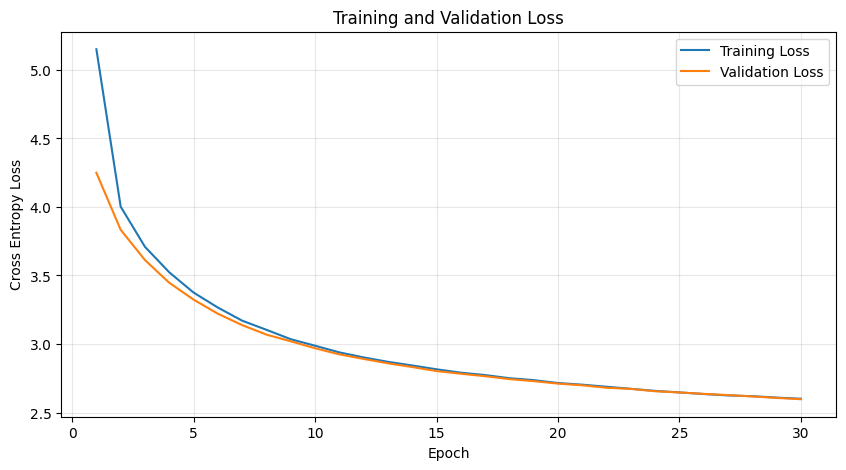

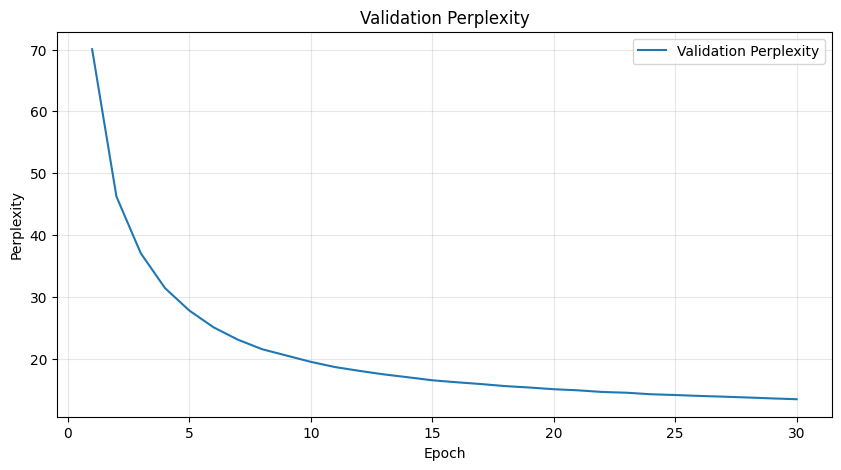

In [20]:

# ==========================================
# LOAD BEST CHECKPOINT
# ==========================================

try:

    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=False
    )

except TypeError:

    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )


model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)
model.eval()


print("Best epoch:", checkpoint["epoch"])

print("Best validation loss:", checkpoint["best_val_loss"])


# ==========================================
# SAVE TRAINING HISTORY
# ==========================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    "/kaggle/working/training_history.csv",
    index=False
)


# ==========================================
# PLOT LOSS CURVES
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")

plt.title("Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


# ==========================================
# PLOT PERPLEXITY
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["validation_perplexity"],
    label="Validation Perplexity"
)

plt.xlabel("Epoch")
plt.ylabel("Perplexity")

plt.title("Validation Perplexity")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [21]:

# ==========================================
# FINAL VALIDATION
# ==========================================

final_results = evaluate_loss(
    model,
    validation_tokens,
    BLOCK_SIZE,
    BATCH_SIZE
)


print("=" * 50)
print("FINAL VALIDATION REPORT")
print("=" * 50)

print("Best epoch:", checkpoint["epoch"])

print("Training tokens:", f"{len(train_tokens):,}")

print("Validation tokens:", f"{len(validation_tokens):,}")

print("Vocabulary size:", VOCAB_SIZE)

print("Model parameters:", f"{total_parameters:,}")

print(
    "Validation loss:",
    round(final_results["loss"], 4)
)

print(
    "Validation perplexity:",
    round(final_results["perplexity"], 4)
)

print(
    "Evaluated transitions:",
    f'{final_results["evaluated_tokens"]:,}'
)

print("Uncovered transitions:", 0)


FINAL VALIDATION REPORT
Best epoch: 30
Training tokens: 606,047,153
Validation tokens: 6,089,728
Vocabulary size: 1000
Model parameters: 653,800
Validation loss: 2.5976
Validation perplexity: 13.4318
Evaluated transitions: 6,089,727
Uncovered transitions: 0


In [22]:

# ==========================================
# LOAD TRAINED TOKENIZER
# ==========================================

tokenizer = BPETokenizer(
    vocab_size=VOCAB_SIZE
)

tokenizer.load(
    DATA_DIR / "tokenizer.json"
)


# ==========================================
# GENERATION FUNCTION
# ==========================================

@torch.inference_mode()
def generate_text(
    model,
    tokenizer,
    prompt,
    max_new_tokens=200,
    temperature=0.8,
    top_k=40
):

    if temperature <= 0:
        raise ValueError("Temperature must be positive.")

    if not prompt.strip():
        raise ValueError("Prompt cannot be empty.")

    model.eval()

    # Convert prompt into token IDs.
    generated_ids = tokenizer.encode(prompt)

    for _ in range(max_new_tokens):

        # Retain the most recent context.
        context = generated_ids[
            -MODEL_CONFIG["max_seq_len"] :
        ]

        input_tensor = torch.tensor(
            context,
            dtype=torch.long,
            device=device
        ).unsqueeze(0)

        # Predict next token.
        logits = model(input_tensor)

        next_logits = logits[0, -1, :].clone()

        # Prevent special tokens from being generated.
        next_logits[PAD_TOKEN_ID] = float("-inf")
        next_logits[UNK_TOKEN_ID] = float("-inf")

        # Temperature.
        next_logits = next_logits / temperature

        # Top-k sampling.
        if top_k is not None:

            k = min(top_k, VOCAB_SIZE)

            values, _ = torch.topk(next_logits, k)

            threshold = values[-1]

            next_logits[
                next_logits < threshold
            ] = float("-inf")

        # Convert logits to probabilities.
        probabilities = torch.softmax(
            next_logits,
            dim=-1
        )

        # Sample next token.
        next_token = torch.multinomial(
            probabilities,
            num_samples=1
        ).item()

        generated_ids.append(next_token)

        # Stop at EOS.
        if next_token == EOS_TOKEN_ID:
            break

    return tokenizer.decode(generated_ids)


# ==========================================
# GENERATE STORY
# ==========================================

prompt = "One morning, a little girl found a mysterious key."

generated_story = generate_text(
    model=model,
    tokenizer=tokenizer,
    prompt=prompt,
    max_new_tokens=200,
    temperature=0.8,
    top_k=40
)


print("=" * 60)
print("GENERATED STORY")
print("=" * 60)

print(generated_story)


# Save generated output.
with open(
    "/kaggle/working/generated_story.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(generated_story)


Tokenizer loaded.
Vocabulary size: 1000
GENERATED STORY
One morning, a little girl found a mysterious key.


